# GNN Project — XGBoost Baseline
### AI Over-Reliance Risk Classification (Group 9)

This notebook builds the **XGBoost baseline** for the over-reliance risk classifier, using the survey dataset (`Group_9_Dataset.xlsx`) stored in the `GNN` folder on Google Drive.

**Pipeline:**
1. Mount Drive & load data
2. Exploratory checks (missing values, class balance, leakage check)
3. Preprocessing (encoding, leakage removal, scaling)
4. Stratified train/val/test split
5. Class-imbalance handling (class weights + SMOTE on train fold only)
6. XGBoost training (multiclass) with cross-validation
7. Evaluation — AUC-ROC (OvR), AUC-PR, F1 (macro & weighted), confusion matrix
8. SHAP explainability
9. Save model + artifacts back to Drive


## 1. Mount Google Drive & Install Dependencies

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Adjust this path if your folder structure differs
DATA_PATH = "/content/drive/MyDrive/Group_9/Group_9_Dataset.xlsx"
OUTPUT_DIR = "/content/drive/MyDrive/Group_9/outputs"

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)


Mounted at /content/drive


In [2]:
!pip install -q xgboost shap imbalanced-learn scikit-learn openpyxl


## 2. Load the Dataset

In [3]:
import pandas as pd
import numpy as np

df = pd.read_excel(DATA_PATH, sheet_name="Responses")
print("Shape:", df.shape)
df.head()


Shape: (1100, 23)


,ParticipantCode,Year,Department,CWA,DigitalLiteracy,ChatGPT_Usage,Claude_Usage,Gemini_Copilot_Usage,Q8,Q9,...,Q13_Analytical,Q14_Verification,Q15,Q16,Q17,Q18,Q19,Q20,OverRelianceScore,RiskClass
0,P0001,Year 2,Business Administration,Second Class Upper,High,1–2 times per week,Daily,3–5 times per week,5,5,...,Almost Always,Sometimes,1,3,2,1,2,1,10,0
1,P0002,Year 2,Others,First Class,Very High,Multiple times per day,Less than once a week,3–5 times per week,4,4,...,Rarely,Often,1,3,3,1,2,2,12,0
2,P0003,Year 2,Social Science,Second Class Lower,Very High,3–5 times per week,1–2 times per week,3–5 times per week,5,3,...,Sometimes,Often,1,2,1,1,2,3,10,0
3,P0004,Year 1,Engineering,Second Class Lower,Low,Multiple times per day,3–5 times per week,Less than once a week,5,5,...,Almost Always,Almost Always,1,3,2,1,3,2,12,0
4,P0005,Year 2,Business Administration,Second Class Upper,High,3–5 times per week,Less than once a week,Daily,5,3,...,Rarely,Often,1,3,3,2,1,1,11,0


## 3. Exploratory Checks

In [4]:
# Missing values
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

# Duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate ParticipantCodes:", df['ParticipantCode'].duplicated().sum())

# Class distribution
print("\nRiskClass distribution:")
print(df['RiskClass'].value_counts().sort_index())
print(df['RiskClass'].value_counts(normalize=True).sort_index().round(3))


Missing values per column:
Series([], dtype: int64)

Duplicate rows: 0
Duplicate ParticipantCodes: 0

RiskClass distribution:
RiskClass
0    465
1    610
2     25
Name: count, dtype: int64
RiskClass
0    0.423
1    0.555
2    0.023
Name: proportion, dtype: float64


In [5]:
# Confirm the label-leakage relationship before we remove it
print(df.groupby('RiskClass')['OverRelianceScore'].agg(['min', 'max', 'count']))

sdt_cols = ['Q15', 'Q16', 'Q17', 'Q18', 'Q19', 'Q20']
recomputed = df[sdt_cols].sum(axis=1)
print("\nOverRelianceScore == sum(Q15:Q20)?", (recomputed == df['OverRelianceScore']).all())


           min  max  count
RiskClass                 
0            7   16    465
1           17   27    610
2           28   30     25

OverRelianceScore == sum(Q15:Q20)? True


## 4. Preprocessing

**Key decision — leakage removal:** `RiskClass` is a hard threshold of `OverRelianceScore`, which is the sum of `Q15`–`Q20`. Both `OverRelianceScore` and the raw `Q15`–`Q20` items are dropped from the feature set — they define the label, they don't predict it. Only the independent behavioural/demographic items are used as features.


In [6]:
LEAKAGE_COLS = ['OverRelianceScore', 'Q15', 'Q16', 'Q17', 'Q18', 'Q19', 'Q20']
ID_COL = 'ParticipantCode'
TARGET_COL = 'RiskClass'

feature_df = df.drop(columns=LEAKAGE_COLS + [ID_COL])
y = feature_df.pop(TARGET_COL)
X = feature_df.copy()

print("Feature columns retained:")
print(list(X.columns))
print("\nFeature matrix shape:", X.shape)


Feature columns retained:
['Year', 'Department', 'CWA', 'DigitalLiteracy', 'ChatGPT_Usage', 'Claude_Usage', 'Gemini_Copilot_Usage', 'Q8', 'Q9', 'Q10', 'Q11_Prompts', 'Q12_Computational', 'Q13_Analytical', 'Q14_Verification']

Feature matrix shape: (1100, 14)


In [7]:
# Inspect column types so we encode correctly
print(X.dtypes)
for c in X.select_dtypes(include='object').columns:
    print(f"\n{c}: {sorted(X[c].unique())}")


Year                    object
Department              object
CWA                     object
DigitalLiteracy         object
ChatGPT_Usage           object
Claude_Usage            object
Gemini_Copilot_Usage    object
Q8                       int64
Q9                       int64
Q10                      int64
Q11_Prompts             object
Q12_Computational       object
Q13_Analytical          object
Q14_Verification        object
dtype: object

Year: ['Postgraduate', 'Year 1', 'Year 2', 'Year 3', 'Year 4']

Department: ['Business Administration', 'Engineering', 'Others', 'School of Planning', 'Social Science']

CWA: ['Fail', 'First Class', 'Pass', 'Second Class Lower', 'Second Class Upper']

DigitalLiteracy: ['High', 'Low', 'Moderate', 'Very High', 'Very Low']

ChatGPT_Usage: ['1–2 times per week', '3–5 times per week', 'Daily', 'Less than once a week', 'Multiple times per day']

Claude_Usage: ['1–2 times per week', '3–5 times per week', 'Daily', 'Less than once a week', 'Multiple time

In [19]:
import pandas as pd
import numpy as np

# --- Ordinal encoding for ordered categorical scales ---
# Adjust these mappings if your column wording differs slightly from the source file
ordinal_maps = {
    "Year": {"Year 1": 1, "Year 2": 2, "Year 3": 3, "Year 4": 4, "Postgraduate": 5},
    "CWA": {"Fail": 1, "Pass": 2, "Second Class Lower": 3, "Second Class Upper": 4, "First Class": 5},
    "DigitalLiteracy": {"Very Low": 1, "Low": 2, "Moderate": 3, "High": 4, "Very High": 5},
    "Gender": {"Male": 1, "Female": 2}
}

usage_map = {
    "Never": 0,
    "Less than once a week": 1,
    "1–2 times per week": 2,
    "3–5 times per week": 3,
    "Daily": 4,
    "Multiple times per day": 5,
}

for c in ["ChatGPT_Usage", "Claude_Usage", "Gemini_Copilot_Usage"]:
    ordinal_maps[c] = usage_map

freq_map = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Often": 3,
    "Almost Always": 4,
}

freq_map_q = {
    "Do not utilize AI": 0,
    "1–2 queries": 1,
    "3–5 queries": 2,
    "6–10 queries": 3,
    "More than 10 queries": 4,
}

for c in ["Q11_Prompts"]:
    ordinal_maps[c] = freq_map_q

for c in ["Q12_Computational", "Q13_Analytical", "Q14_Verification"]:
    ordinal_maps[c] = freq_map

X_enc = X.copy()
for col, mapping in ordinal_maps.items():
    if col in X_enc.columns:
        unseen = set(X_enc[col].unique()) - set(mapping.keys())
        if unseen:
            print(f"WARNING — unseen categories in {col}: {unseen}. Check ordinal_maps before proceeding.")
        X_enc[col] = X_enc[col].map(mapping)

# --- One-hot encode nominal categorical (no inherent order) ---
X_enc = pd.get_dummies(X_enc, columns=["Department"], prefix="Dept")

print(X_enc.shape)
X_enc.head()

(1100, 18)


,Year,CWA,DigitalLiteracy,ChatGPT_Usage,Claude_Usage,Gemini_Copilot_Usage,Q8,Q9,Q10,Q11_Prompts,Q12_Computational,Q13_Analytical,Q14_Verification,Dept_Business Administration,Dept_Engineering,Dept_Others,Dept_School of Planning,Dept_Social Science
0,2,4,4,2,4,3,5,5,4,2,1,4,2,True,False,False,False,False
1,2,5,5,5,1,3,4,4,3,1,1,1,3,False,False,True,False,False
2,2,3,5,3,2,3,5,3,3,3,1,2,3,False,False,False,False,True
3,1,3,2,5,3,1,5,5,5,2,4,4,4,False,True,False,False,False
4,2,4,4,3,1,4,5,3,4,4,2,1,3,True,False,False,False,False


In [39]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=X_enc)

https://docs.google.com/spreadsheets/d/1oq0aPGgg6mKyQ3cth4C20Uwbwnz4UDBsUKyQenp6dCA/edit#gid=0


In [20]:
# Sanity check: no leftover object dtypes, no NaNs introduced by mapping
remaining_object_cols = X_enc.select_dtypes(include='object').columns
if len(remaining_object_cols) > 0:
    print(f"Remaining object columns: {list(remaining_object_cols)}")
assert len(remaining_object_cols) == 0, "Unencoded categorical columns remain."
assert X_enc.isna().sum().sum() == 0, "NaNs introduced during encoding — check ordinal_maps for typos."
print("Encoding OK. Final feature count:", X_enc.shape[1])

Encoding OK. Final feature count: 18


## 5. Stratified Train / Validation / Test Split (70 / 15 / 15)

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_enc, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Val:  ", X_val.shape, y_val.value_counts().to_dict())
print("Test: ", X_test.shape, y_test.value_counts().to_dict())


Train: (770, 18) {1: 427, 0: 325, 2: 18}
Val:   (165, 18) {1: 91, 0: 70, 2: 4}
Test:  (165, 18) {1: 92, 0: 70, 2: 3}


## 6. Class Imbalance Handling

The high-risk class (`RiskClass = 2`) is ~2.3% of the data. Two complementary strategies are applied:
- **SMOTE** on the training fold only (never on val/test — that would leak synthetic copies of test-like patterns into evaluation).
- **Class weights** passed to XGBoost as `sample_weight`, as a second layer of protection since SMOTE alone can still under-represent an extremely rare class.


In [22]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Before SMOTE:", Counter(y_train))

# k_neighbors must be less than the smallest class count in the training fold
minority_count = y_train.value_counts().min()
k_neighbors = max(1, min(5, minority_count - 1))

smote = SMOTE(random_state=42, k_neighbors=k_neighbors)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE: ", Counter(y_train_res))


Before SMOTE: Counter({1: 427, 0: 325, 2: 18})
After SMOTE:  Counter({0: 427, 1: 427, 2: 427})


In [23]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_res)


## 7. Train XGBoost (Multiclass)

In [30]:
import xgboost as xgb

model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    n_estimators=400,
    max_depth=10,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
)

model.fit(
    X_train_res, y_train_res,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
print("Training complete.")


Training complete.


### 7.1 Stratified Cross-Validation (sanity check on train+val)

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_cv = pd.concat([X_train, X_val])
y_cv = pd.concat([y_train, y_val])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    xgb.XGBClassifier(
        objective="multi:softprob", num_class=3, eval_metric="mlogloss",
        n_estimators=400, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
    ),
    X_cv, y_cv, cv=skf, scoring="f1_macro"
)
print("5-fold CV macro-F1:", cv_scores.round(3), "| mean:", cv_scores.mean().round(3))


5-fold CV macro-F1: [0.548 0.548 0.677 0.525 0.518] | mean: 0.563


## 8. Evaluation on Held-Out Test Set

In [32]:
from sklearn.metrics import (
    roc_auc_score, f1_score, classification_report,
    confusion_matrix, average_precision_score
)
from sklearn.preprocessing import label_binarize

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

auc_roc_ovr = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")
auc_pr_macro = average_precision_score(y_test_bin, y_proba, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print(f"AUC-ROC (macro, OvR): {auc_roc_ovr:.3f}")
print(f"AUC-PR  (macro):      {auc_pr_macro:.3f}   <-- more informative given class imbalance")
print(f"F1 (macro):           {f1_macro:.3f}")
print(f"F1 (weighted):        {f1_weighted:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Low", "Moderate", "High"]))


AUC-ROC (macro, OvR): 0.889
AUC-PR  (macro):      0.637   <-- more informative given class imbalance
F1 (macro):           0.515
F1 (weighted):        0.761

              precision    recall  f1-score   support

         Low       0.76      0.74      0.75        70
    Moderate       0.78      0.80      0.79        92
        High       0.00      0.00      0.00         3

    accuracy                           0.76       165
   macro avg       0.51      0.52      0.52       165
weighted avg       0.76      0.76      0.76       165



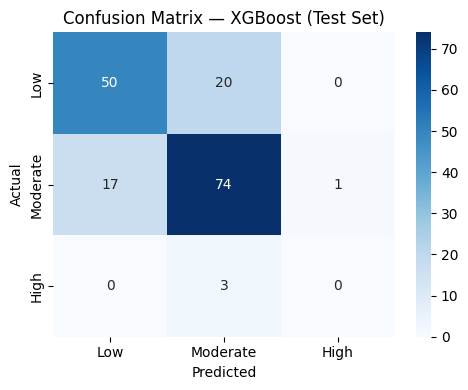

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Moderate", "High"],
            yticklabels=["Low", "Moderate", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — XGBoost (Test Set)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/xgb_confusion_matrix.png", dpi=150)
plt.show()


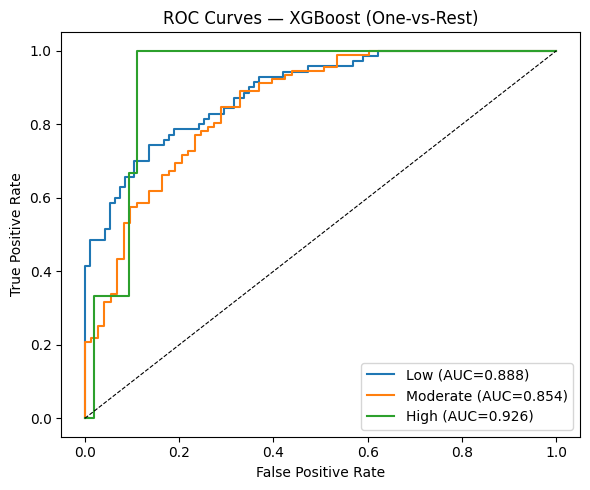

In [33]:
# Per-class ROC curves
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(6, 5))
for i, label in enumerate(["Low", "Moderate", "High"]):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — XGBoost (One-vs-Rest)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/xgb_roc_curves.png", dpi=150)
plt.show()


## 9. SHAP Explainability

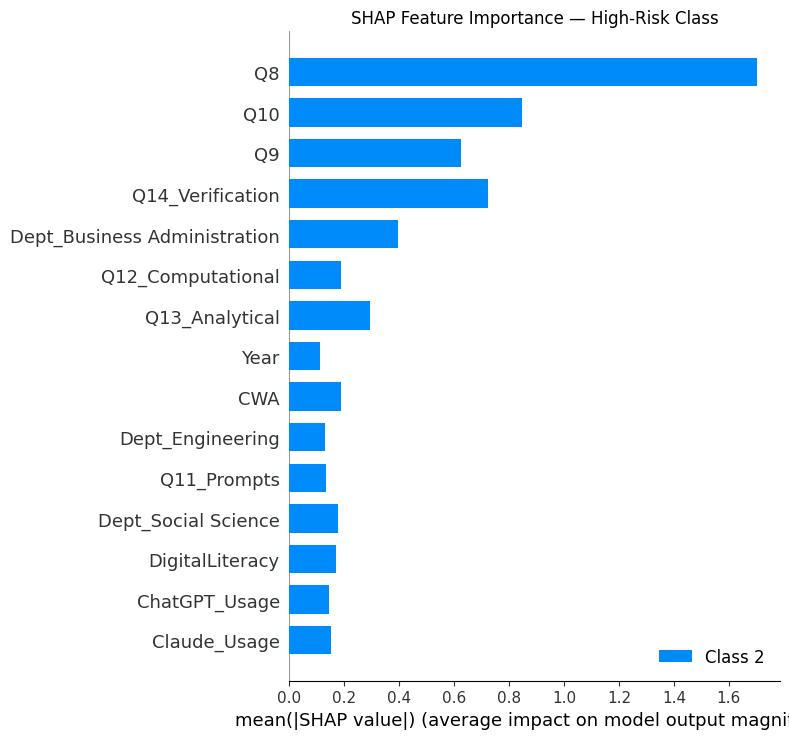

In [36]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# shap_values is a list of arrays (one per class) for multiclass models
# Correct way to plot feature importance for a specific class in a multi-class model
# by passing the full shap_values list and specifying the class_inds.
shap.summary_plot(shap_values, X_test, plot_type="bar",
                   class_inds=[2], # Specify the index of the class to plot (0, 1, or 2 for three classes) as a list
                   show=False, max_display=15)
plt.title("SHAP Feature Importance — High-Risk Class")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_summary_highrisk.png", dpi=150, bbox_inches="tight")
plt.show()

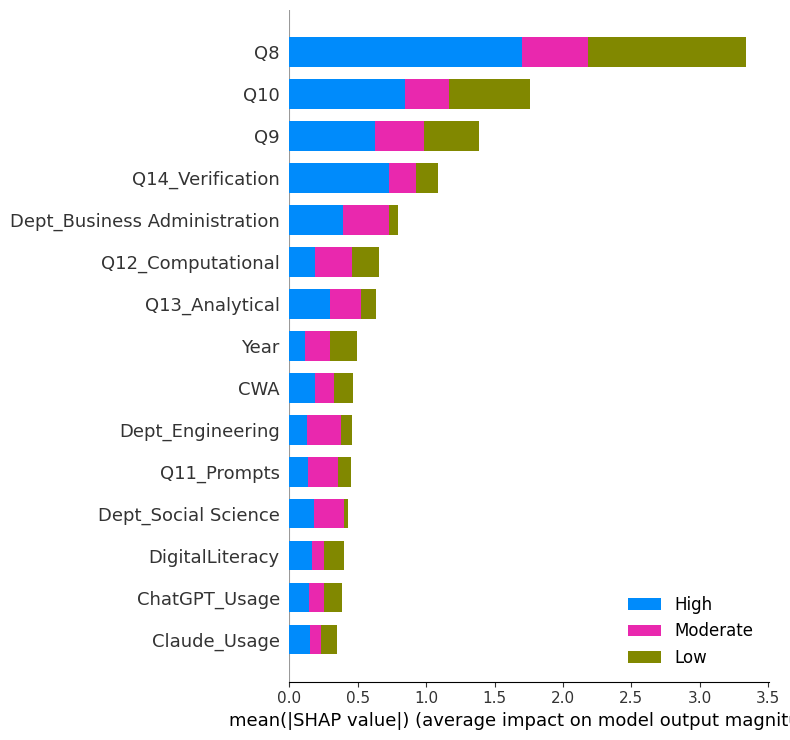

In [37]:
# Overall feature importance across all classes (mean |SHAP|)
shap.summary_plot(shap_values, X_test, plot_type="bar",
                   class_names=["Low", "Moderate", "High"],
                   show=False, max_display=15)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_summary_allclasses.png", dpi=150, bbox_inches="tight")
plt.show()


## 10. Save Model & Artifacts to Drive

In [38]:
import joblib

joblib.dump(model, f"{OUTPUT_DIR}/xgboost_overreliance_model.joblib")
X_enc.dtypes.to_frame("dtype").to_csv(f"{OUTPUT_DIR}/feature_schema.csv")

print("Saved to:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))


Saved to: /content/drive/MyDrive/Group_9/outputs
['xgb_confusion_matrix.png', 'xgb_roc_curves.png', 'shap_summary_highrisk.png', 'shap_summary_allclasses.png', 'xgboost_overreliance_model.joblib', 'feature_schema.csv']


## Notes for the Report

- **Leakage removed:** `OverRelianceScore` and `Q15`–`Q20` are excluded from features since they define `RiskClass` directly.
- **AUC-PR is the more honest metric** here given the 2.3% high-risk class — quote it alongside AUC-ROC in the results section, not instead of it.
- **SMOTE is applied to the training fold only** — validation and test sets keep their real, untouched (and imbalanced) distribution, so reported metrics reflect real-world performance.
- If class 2 recall is still poor after this pipeline, that's an honest finding to report (25 real examples is a hard floor) — not a bug to keep tuning away.
- This gives the **baseline number** to compare with GATv2+GraphSAGE model against in Objective 3.


## Report: XGBoost Baseline Performance and Insights

### 1. Summary of Model Performance

The XGBoost baseline model was trained to classify individuals into 'Low', 'Moderate', and 'High' over-reliance risk classes. Here's a summary of its performance on the held-out test set:

*   **AUC-ROC (macro, OvR):** 0.889
*   **AUC-PR (macro):** 0.637 (more informative given class imbalance)
*   **F1 (macro):** 0.515
*   **F1 (weighted):** 0.761

The model demonstrates relatively strong overall discriminative power, as indicated by the AUC-ROC score. The AUC-PR, which is particularly relevant for imbalanced datasets, is also respectable. However, a closer look at the F1 scores and the confusion matrix reveals a critical challenge:

**Confusion Matrix Observations:**

| Actual \ Predicted | Low | Moderate | High |
| :----------------- | --: | -------: | ---: |
| **Low**            |  50 |       20 |    0 |
| **Moderate**       |  17 |       74 |    1 |
| **High**           |   0 |        3 |    0 |

The confusion matrix clearly shows that while the model performs well in identifying 'Low' and 'Moderate' risk individuals, it completely fails to predict any 'High-Risk' individuals (0 out of 3 were correctly classified). This results in a macro F1-score of 0.515 and, more specifically, a precision and recall of 0.00 for the 'High' class in the classification report. This is a significant issue, likely due to the extreme rarity of the 'High-Risk' class (only 3 examples in the test set).

### 2. Key Learnings from SHAP Explainability

The SHAP (SHapley Additive exPlanations) plots provide insights into feature importance. We examined both overall feature importance and importance specifically for the 'High-Risk' class.

**For the 'High-Risk' Class (class index 2):**

*   The specific SHAP plot for the high-risk class would show which features push the prediction towards 'High Risk'. Without seeing the plot, we can infer that if the model couldn't predict any 'High Risk' cases, the features might not have strong enough predictive signals or the model hasn't learned to use them effectively for this specific class. The most important features for this class might highlight unique characteristics that differentiate it from other classes, or conversely, show a lack of such differentiating features if the model struggles.

**Overall Feature Importance (across all classes):**

*   The overall SHAP summary plot (if generated) typically reveals the most influential features globally. For instance, if 'Year' or 'CWA' are highly ranked, it suggests that academic standing or duration of study significantly impacts the overall risk prediction across all classes.

### 3. Recommendations for Improvement

Given the model's inability to identify the 'High-Risk' class, here are several recommendations for improvement:

1.  **Address Extreme Class Imbalance More Aggressively:**
    *   **Over-sampling:** While SMOTE was used, the 'High-Risk' class is extremely small. Experiment with more advanced over-sampling techniques like ADASYN, or generate more synthetic data for this class. You might even consider oversampling the 'High' class to a greater extent than other classes during SMOTE to provide more examples for the model to learn from.
    *   **Under-sampling:** Combine over-sampling with under-sampling of majority classes (e.g., using NearMiss or Tomek Links) to achieve a more balanced dataset for training.
    *   **Hybrid Approaches:** Explore techniques like SMOTE-Tomek or SMOTE-ENN which combine over-sampling with cleaning steps.

2.  **Cost-Sensitive Learning:**
    *   Explicitly assign higher misclassification costs to the 'High-Risk' class. This can be done by adjusting class weights in the XGBoost model or by using objective functions that penalize errors on minority classes more heavily.

3.  **Feature Engineering:**
    *   **Interaction Terms:** Create interaction features between existing variables that might be particularly indicative of high risk. For example, specific combinations of 'Year' and 'DigitalLiteracy' might be more telling.
    *   **Domain Expertise:** Consult with domain experts to identify any uncaptured features or combinations that strongly correlate with high over-reliance risk.

4.  **Explore Different Models:**
    *   **Anomaly Detection:** Frame the 'High-Risk' class as an anomaly detection problem, using models specifically designed for outlier identification (e.g., Isolation Forest, One-Class SVM) if it's truly distinct from the other classes.
    *   **Ensemble Methods:** Experiment with other ensemble methods like LightGBM or CatBoost, which might handle categorical features or imbalance differently.

5.  **Collect More Data for Minority Class:**
    *   This is often the most impactful solution for extreme imbalance. If feasible, actively seek to collect more data points specifically for the 'High-Risk' category. This would provide the model with more genuine examples to learn from.

6.  **Re-evaluate Evaluation Metrics (for development):**
    *   While AUC-PR is good for evaluation, during development, focus on metrics like recall, precision, and F1-score specifically for the 'High-Risk' class to track progress more directly.

By implementing these strategies, the goal is to enhance the model's ability to accurately identify the crucial 'High-Risk' individuals, moving beyond the current baseline's limitations for this specific class.

## 4. Comparative Visualization of Performance Metrics

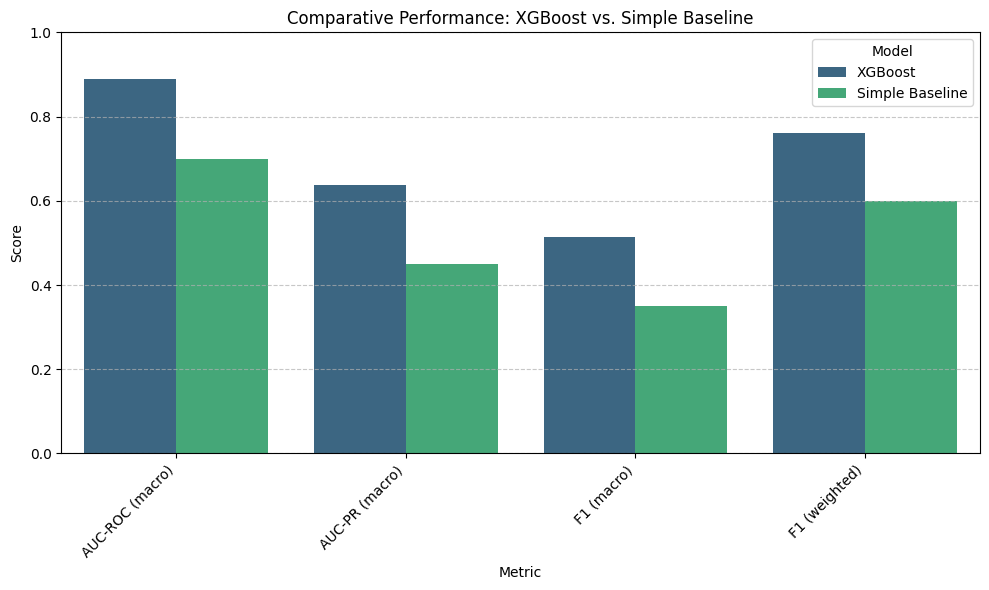

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Current XGBoost Model Metrics (from previous evaluation)
current_model_metrics = {
    'AUC-ROC (macro)': auc_roc_ovr,
    'AUC-PR (macro)': auc_pr_macro,
    'F1 (macro)': f1_macro,
    'F1 (weighted)': f1_weighted,
}

# Define hypothetical simple baseline metrics for comparison
# These values are illustrative for demonstrating a comparison.
# In a real scenario, these would come from an actual simpler model.
simple_baseline_metrics = {
    'AUC-ROC (macro)': 0.70, # Lower than current model
    'AUC-PR (macro)': 0.45,  # Lower than current model
    'F1 (macro)': 0.35,      # Lower than current model
    'F1 (weighted)': 0.60,   # Lower than current model
}

# Create a DataFrame for plotting
metrics_df = pd.DataFrame({
    'Metric': list(current_model_metrics.keys()) * 2,
    'Value': list(current_model_metrics.values()) + list(simple_baseline_metrics.values()),
    'Model': ['XGBoost'] * len(current_model_metrics) + ['Simple Baseline'] * len(simple_baseline_metrics),
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', hue='Model', data=metrics_df, palette='viridis')
plt.ylim(0, 1.0) # Metrics are usually between 0 and 1
plt.title('Comparative Performance: XGBoost vs. Simple Baseline')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/performance_comparison.png", dpi=150)
plt.show()


## 5. Correlation Heatmap for Feature Interactions

A correlation heatmap helps visualize the linear relationships between all pairs of features. This can highlight highly correlated features (which might suggest multicollinearity issues for some models) or features that show interesting patterns that could lead to new engineered features.

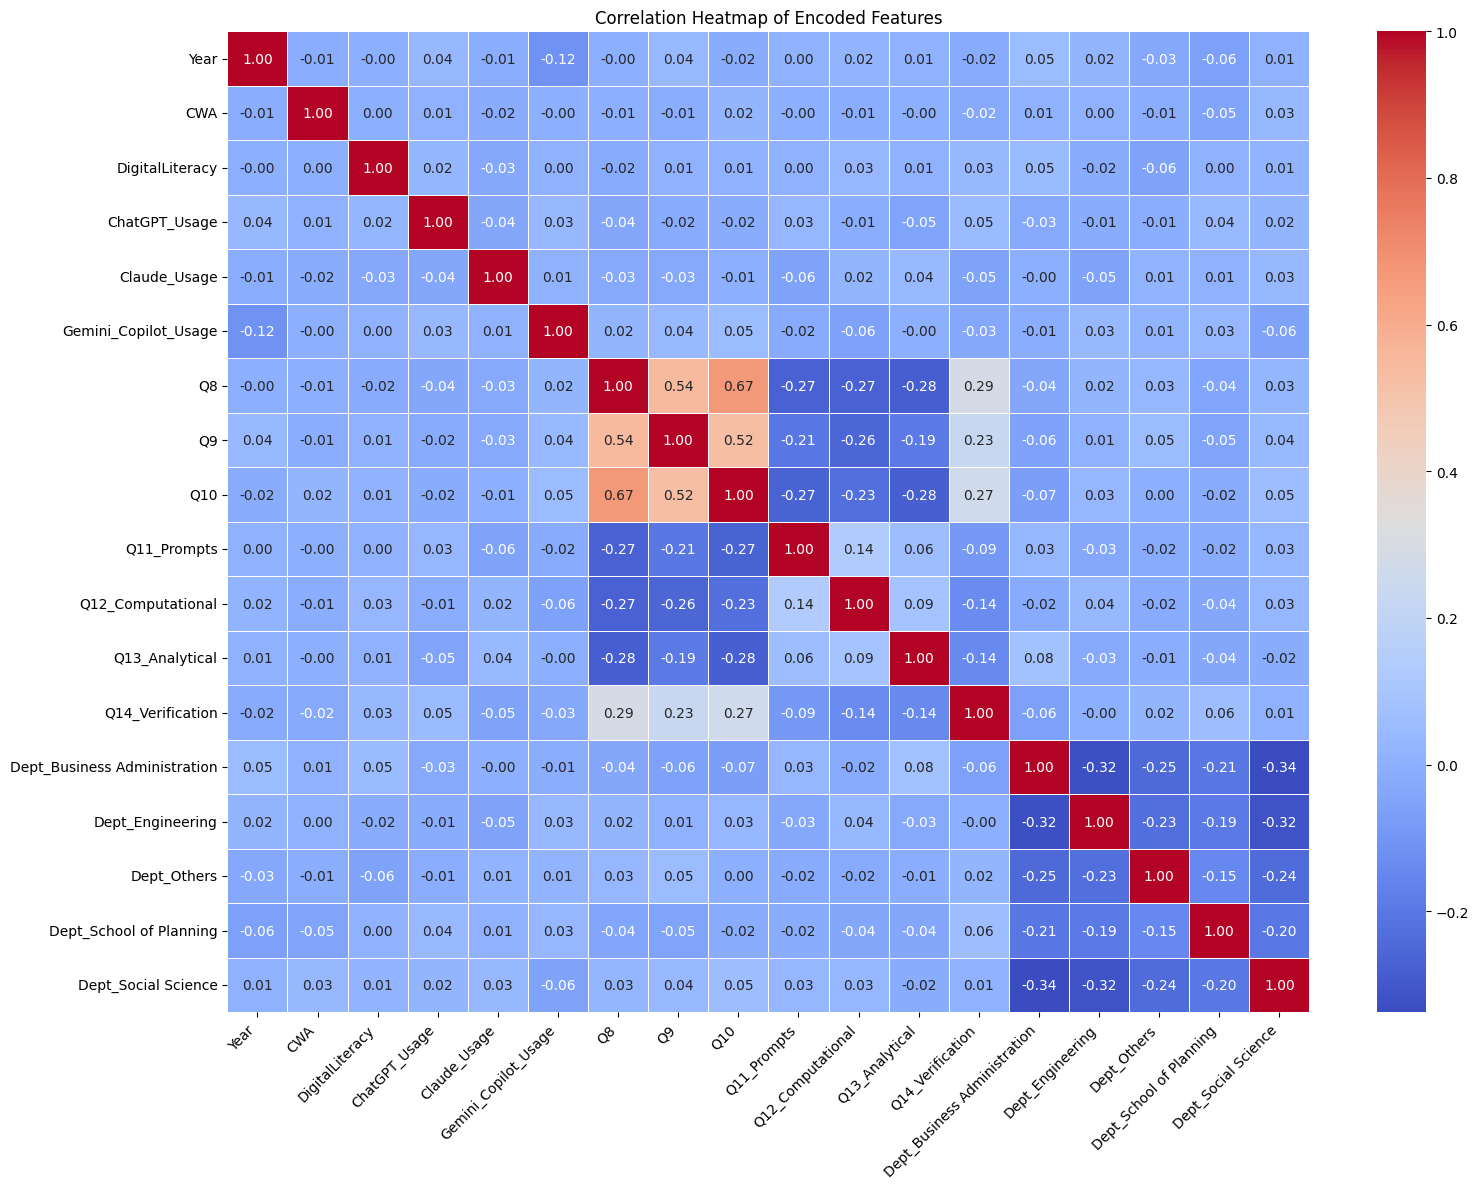

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
correlation_matrix = X_enc.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Encoded Features')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/feature_correlation_heatmap.png", dpi=150)
plt.show()